# <span style="color:magenta">1. Setup and Config</span>

In [1]:
#import neccasary libraries
import torch
from pathlib import Path
import os
import sys
root_dir = Path.cwd().parent
sys.path.append(str(root_dir))
import importlib

from src import custom_data as cd

Importing the necessary library:  
1. `torch`- it is framwork to do my whole project for deeplearning    
2. `nn`- for model architecture and other moduls  
3. `Path` - to determine current working directory which is important to link with other src files and talking with directories.
4. `sys` - it interact with python interprator to access python command, python path and python runtime.
5. `os` - it helps us to talk with machine's operating system, specifically when we want to interact with path directory and file(to access files and directory)
5. `importlib`- for reloading src files.

### **1.1 Color configure**

In [2]:
#color configresion for printing
HEADER = '\033[95m'
ORANGE = '\033[38;5;208m'
OKBLUE = '\033[94m'
OKCYAN = '\033[96m'
OKGREEN = '\033[92m'
WARNING = '\033[93m'
FAIL = '\033[91m'
ENDC = '\033[0m'
BOLD = '\033[1m'
UNDERLINE = '\033[4m'

### **1.2 Device config**
Device agnostice are isential in deep learning pyTorch which speed up the speed of the computation to train the model.  befor we try to write the code i have to know which device(weather GPU if avialiable or CPU defualt device) i will use for my model. 

In [3]:
#device diagnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"{OKGREEN}Using device: {ENDC}{UNDERLINE}{device}{ENDC}")    

Using device: cpu


### **1.3 Download the dataset**

In [4]:
import requests      #This is thired party library of python used to communicate with internet.
import zipfile       #This is thired party library of python used to work with zip files.
# Setup path to data folder
data_path = Path.cwd().parent / "Dataset" / "food_images"
image_path = data_path / "pizza_steak_sushi"

"""This if else block of code works for downloading the dataset. if the dataset directory there in my local computer the downloading is not necessary but if not the dataset will be download to the pointing place by creating the dirctory for the data."""

if image_path.is_dir():                           # is.dir()- is built in python library which used to check the given path weather or not directory/folder.
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)
    
    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...") 
        zip_ref.extractall(image_path)


/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi directory exists.


In [5]:
def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory
  
  Returns:
    A print out of:
      number of subdiretories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for root_directory, directory_name, filenames in os.walk(dir_path):             #have tree like structure to access and organize the data structure.
    print(f"{root_directory} have {len(directory_name)} directories and {len(filenames)} files.")

<span style="color:magenta">**os.walk():**</span> method accepts one parameter of <u>**path object**</u> and return s:
 - Root directory path.
 - The number of directories and number of files in the root directory.
 - This processes continous untile all directory and files are visited.

### **1.4 Train/Test data**

In [6]:
#set up the training and testing dataset
train_dir = image_path/"train"
test_dir = image_path/"test"


# walk through the training and testing directory
walk_through_dir(data_path.parent)     

/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset have 1 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images have 1 directories and 1 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi have 2 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test have 3 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/pizza have 0 directories and 25 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/sushi have 0 directories and 31 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak have 0 directories and 19 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train have 3 directories and 0 files.
/home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train/p

My dataset have 300 images. 225 for train dataset and 75 images for test dataset. specifically there some class imbalance but it is acceptable(the difference is small), pizza = 78 + 25 = 103, sushi = 31 + 72 = 103 and steak = 19 + 75 = 94 thus the total image of pizza and sushi exactly same(class ballanced) but steak are slightly smaller than both of the two datasets.

Random image path: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak/690177.jpg
Image class: steak
Image height: 512
Image width: 382


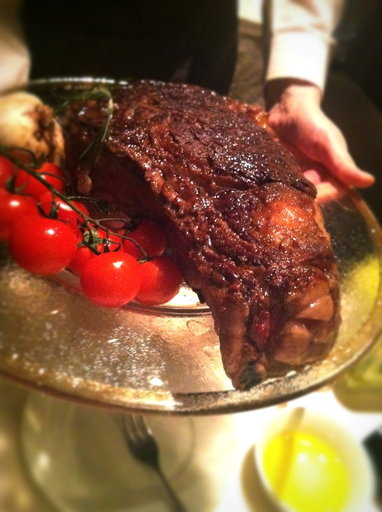

Random image path: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test/steak/690177.jpg
Image class: steak
Image height: 512
Image width: 382


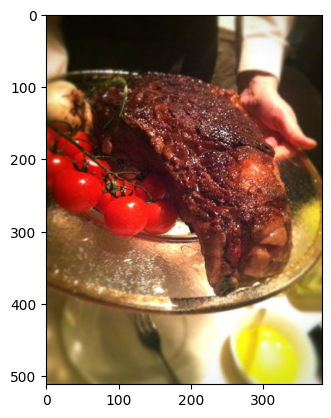

In [7]:
cd = importlib.reload(cd)

image_path_list = list(image_path.glob("*/*/*.jpg"))     #three depths of folders to get to the images
# image_path_list = list(image_path.glob("**/*.jpeg"))   #any depth of the folder are searched for jpeg images
image_diplay = cd.show_random_image(image_path_list)       

display(image_diplay)

#or i can do it like this using matplotlib
import matplotlib.pyplot as plt
import numpy as np
image = np.asarray(cd.show_random_image(image_path_list) )  #also show using matplotlib modul
plt.imshow(image)
plt.show()

# <span style="color:magenta">2. Transform the data</span>
Download, load and transform the dataset from torchvision module- torchvisioin are a parts of dataset module which contains only vision based datas.  
There are also other time of data from dataset module like torchaudio(audio datas), torchtext(text based datas).

In [8]:
#libraries
from torchvision import datasets, transforms
import random
from PIL import Image #to manupilate the image data.

<u>dataset</u>: is all about what data is load, and <u>dataloader</u>: are usfull for loading the data to train the model. The whole dataset are loaded to the model by batch. 

<span style="color:red">Transforming</span>: is preprocessing of data befor using for training the models. during transforming there are series of activities.   
1. resize the image - using transform.resize() all image size must the same for the model.
2. flip image ranodmly - transform.randomHorizontalFlip() - for data augmentation.
3. turn the image PIL(python image library)(pillow) image to tensor.   

`Image` are from PIL(in older version known as Python Image Library but now Pillow Library)  used to manipulate and process the image(open image, read image data, resize image data, convert color format, save the image)

In [9]:
#first transform the image
transform_image = transforms.Compose([
    #resize the image to 64 by 64
    transforms.Resize((64,64)),

    #flip image horizontally for data augmentation
    transforms.RandomHorizontalFlip(p=0.5),

    #then turn it into a tensor
    transforms.ToTensor()
])

There are some similarity between (k -are the number of element we want to randomly selected)
1. <span style="color:cyan">**random.choice(list)**</span>- have on parameters and return on random element from the list.
2. <span style="color:cyan">**ranodm.sample(list, k)**</span>- have two parameters and can return more than one element without replacment(no reapeat elements). 
3. <span style="color:cyan"> **ranodm.choices(list, k)**</span>- have also two parameters and can retun more than one element with replacment(one element may selected more than one).

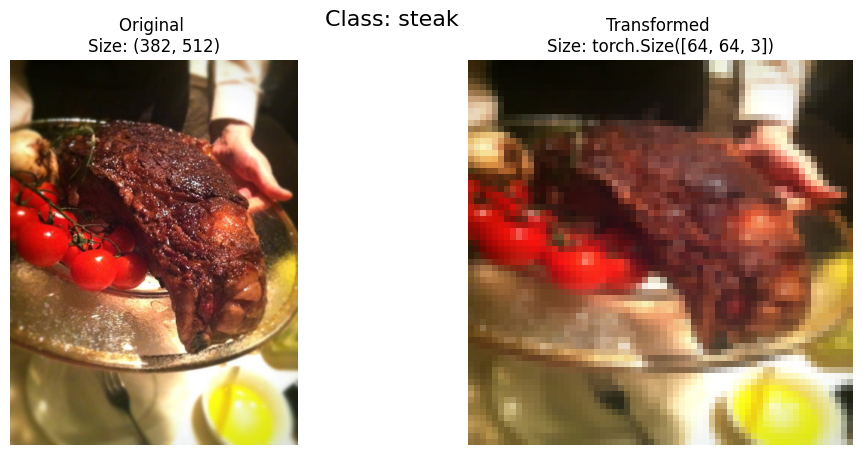

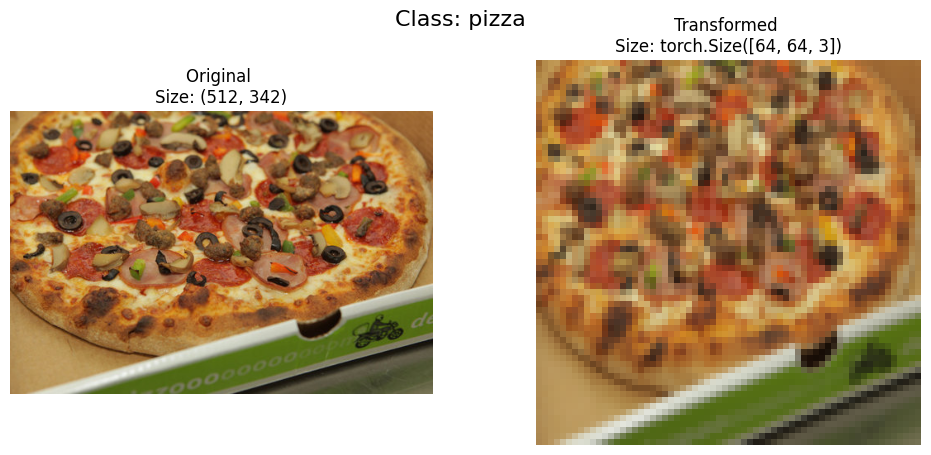

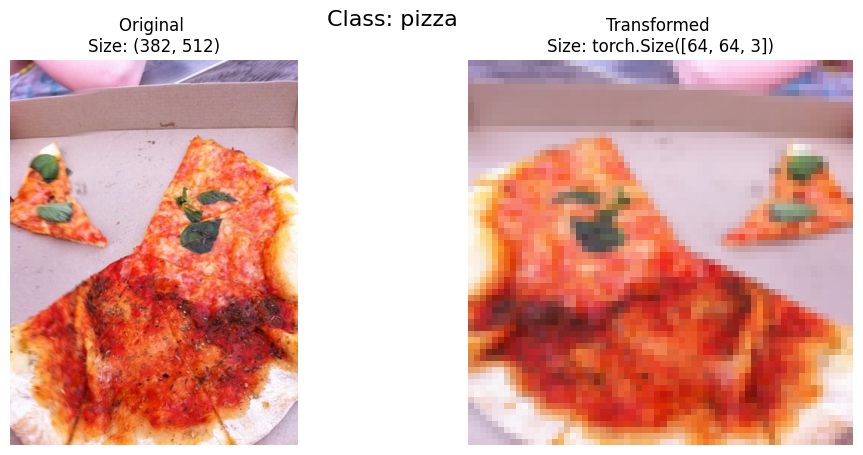

In [10]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):

    random.seed(seed)     #it used for reproducablity, when we run the code giving exactly the same output.
    
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2 , figsize=(12, 5))
            ax[0].imshow(f) 
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Transform and plot image
            # Note: permute() will change shape of image to suit matplotlib 
            # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            transformed_image = transform(f).permute(1, 2, 0) 
            ax[1].imshow(transformed_image) 
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, 
                        transform=transform_image, 
                        n=3)

## <span style="color:magenta">3. Loading dataset</span>

<span style="color:red">ImageFolder: </span> are pyTorch function found it dataset module and it used for manipulation of datas(images) - transform image.  
-It loades image from folder, retun image and label, assign label based on folder.

### **3.1 setup the dataset using ImageFolder**

In [11]:
# Use ImageFolder to create dataset(s)
train_data = datasets.ImageFolder(root=train_dir,                  # target folder of images
                                  transform=transform_image,       # transforms to perform on data (images)
                                  target_transform=None)           # transforms to perform on labels (if necessary)

test_data = datasets.ImageFolder(root=test_dir, 
                                 transform=transform_image)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 225
    Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 75
    Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


From the above output:  
->train dataset have 225 images    
->test dataset have 75 images    
->one image are transformed to a size of <span style="color:orange">[height:64, width:64]</span> and randomly(half chance) horzontally fliped. 

In [12]:
first_image = train_data[0][0]                                    #first element of the tuple is the image data and second element is the label
print(f"\nShape of Torch: {first_image.shape} <--default format of PyTorch is [C, H, W]")
image, label = train_data[0]
print(f"Shape after permuted: {image.permute(1, 2, 0).shape} <--suitable for matplotlib [H, W, C]")

"""permute are important here to change the shape of the image to suit matplotlib because PyTorch default is [C, H, W]-->[CHW or color_channel, height, width] but Matplotlib expectes [H, W, C]--> [height, width, color_channel], to be show the image using matplotlib the shape format should be [H, W, C] format."""
print(f"Label: {label}")
# plt.imshow(image.permute(1, 2, 0))    
# plt.axis("off")
# plt.show()


# for example train dataset have 225 images  then the first image is accessed by indexed 


Shape of Torch: torch.Size([3, 64, 64]) <--default format of PyTorch is [C, H, W]
Shape after permuted: torch.Size([64, 64, 3]) <--suitable for matplotlib [H, W, C]
Label: 0


In [13]:
class_name_array = train_data.classes
print(f"Types of train data: {type(train_data)}")
print(f"Folder(each class) name of train data: {class_name_array}")


class_name_dic = train_data.class_to_idx
print(f"Class name type as dictionary: {type(class_name_dic)}")
print(f"The class names with indexing: {class_name_dic}")

Types of train data: <class 'torchvision.datasets.folder.ImageFolder'>
Folder(each class) name of train data: ['pizza', 'steak', 'sushi']
Class name type as dictionary: <class 'dict'>
The class names with indexing: {'pizza': 0, 'steak': 1, 'sushi': 2}


In [14]:
img, label = train_data[0][0], train_data[0][1]
# print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image shape: torch.Size([3, 64, 64])
Image datatype: torch.float32
Image label: 0
Label datatype: <class 'int'>


In [15]:
print(f"The type of image: {type(img)}")                # this is the feature of the first image of the train dataset.
print(f"The type of output(target): {type(label)}")     # What would be the type of output.

The type of image: <class 'torch.Tensor'>
The type of output(target): <class 'int'>


Here the <span style="color:magenta">data type</span> of the target variable of train data is <span style="color:red">torch tensors</span>, while the data type of the target(Label) variable is <span style="color:red">int(integer)</span>.

### **3.2 Load dataset Using dataloader**

<span style="color:orange">dataloader:</span> are a `torch.utils.data` library which used to load the dataset in to our code by wrapping into batchs.    
It is dataset sampler for the model.
Some arguments in dataloader:   
- <span style="color:cyan">dataset</span> – what data you want to load  
- <span style="color:cyan">batch_size</span> – number of images loaded in one cycle  
- <span style="color:cyan">shuffle (boolean)</span> – order randomness of the data  
- <span style="color:cyan">num_workers</span> – how many subprocesses to use for data loading

In [16]:
from torch.utils.data import DataLoader
#train data
train_dataloader = DataLoader(dataset=train_data, 
                            batch_size=1, 
                            num_workers=1,
                            shuffle=True)

#Test data loader
test_dataloader = DataLoader(dataset=test_data, 
                             batch_size=1,
                             num_workers=1, 
                             shuffle=False)

### Load Image from custom dataset

In [17]:
#import libraries
from typing import Tuple, Dict, List
import pathlib
from torch.utils.data import Dataset

In [18]:
#make custom function to get the class name in list and dictionary

def get_class(directory) ->Tuple[List[str], Dict[str, int]]:              #Type hinting (type annotation) used for better code readability and to help with debugging. it is expecting output of the function.

    classes = sorted(entry.name for entry in list(os.scandir(directory)) if entry.is_dir())

    #if there is not directory in the given path raise error
    if not classes:
        raise FileNotFoundError(f"Could't found any class in {directory}.")
    
    class_to_index = {cls_name: i for i, cls_name in enumerate(classes)}

    return classes, class_to_index

In [19]:
class_name, class_indexed_name = get_class(image_path/"train")
print(class_name)
print(class_indexed_name)

['pizza', 'steak', 'sushi']
{'pizza': 0, 'steak': 1, 'sushi': 2}


In [20]:
# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):             #manually representation of imageFolder class of PyTorch,
    
    # 2. Initialize with a targ_dir and transform (optional) parameter
    def __init__(self, targ_dir: str, transform=None) -> None:
        
        # 3. Create class attributes
        # Get all image paths
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))     #note: you'd have to update this if you've got .png's or .jpeg's
        # Setup transforms
        self.transform = transform
        # Create classes and class_to_idx attributes
        self.classes, self.class_to_idx = get_class(targ_dir)

    # 4. Make function to load images
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path) 
    
    # 5. Overwrite the __len__() method (optional but recommended for subclasses of torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)
    
    # 6. Overwrite the __getitem__() method (required for subclasses of torch.utils.data.Dataset)
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name     # expects path in data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Transform if necessary
        if self.transform:
            return self.transform(img), class_idx # return data, label (X, y)
        else:
            return img, class_idx     # return data, label (X, y)

In [21]:
#now transform the prepared images 

#for train data
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

#for test data(for test data we don't want to do data augmentation)
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()])

In [22]:
#now initialize the costom class for train and test data

train_data_custom =  ImageFolderCustom(targ_dir=train_dir, 
                                       transform=train_transform)
test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                    transform=test_transform)

In [23]:
# print(train_data_custom.classes, test_data_custom.class_to_idx)
print(len(train_data_custom) == len(train_data))
print(len(test_data_custom) == len(test_data))
print(train_data_custom.classes == train_data.classes)

True
True
True


In [24]:
#about random.sample and random.choice() is selecting random sequence and random one element from the squence respectively.

# 1. Take in a Dataset as well as a list of class names
def display_random_images(dataset: torch.utils.data.dataset.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          row = None,
                          columns = None,
                          display_shape: bool = True,
                          seed: int = None):
    
    # 2. Adjust display if n too high
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")
    
    # 3. Set random seed
    if seed:
        random.seed(seed)

    # 4. Get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # 5. Setup plot
    plt.figure(figsize=(12, 6))

    # 6. Loop through samples and display random samples 
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust image tensor shape for plotting: [color_channels, height, width] -> [ height, width, color_channels]
        targ_image_adjust = targ_image.permute(1, 2, 0)
        
        # Plot adjusted samples
        plt.subplot(row, columns, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        plt.tight_layout()
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)

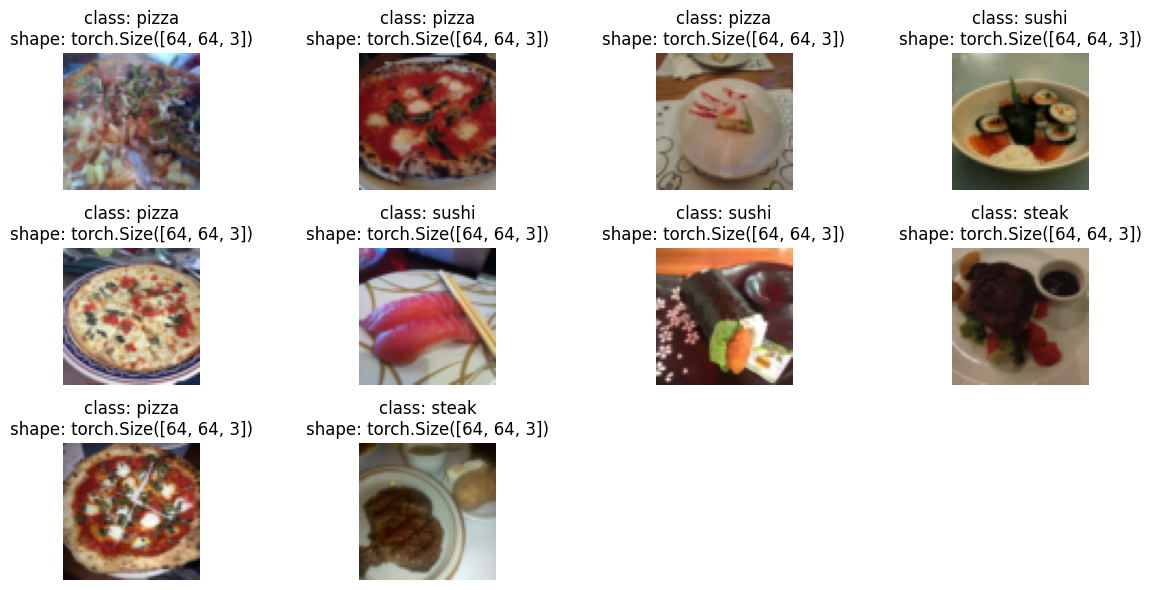

In [25]:
# Display random images from ImageFolder created Dataset
display_random_images(train_data, 
                      n=10, 
                      row = 3,
                      columns = 4,
                      classes=class_name,
                      seed=None)

# <span style="color:magenta">3. Custom data into Dataloader</span>

In [26]:
train_custom_dataloader = DataLoader(dataset = train_data_custom, 
                                    batch_size=1, 
                                    num_workers=0,     # All process of the data are pass through one main process(one path).
                                    shuffle=True)      # train the model without identify the order pattern of the data, it is good for training the model.
test_custom_dataloader = DataLoader(dataset=test_data_custom,
                                    batch_size=1,
                                    num_workers=0,   
                                    shuffle=False)    #for test data for reproducablity shufle must be false.

In [27]:
for image, label in train_custom_dataloader:
    print(f"Image batch shape: {image.shape}")
    print(f"Label batch shape: {label.shape}")
    break

Image batch shape: torch.Size([1, 3, 64, 64])
Label batch shape: torch.Size([1])


## **Data Augmentation**

<span style="color:cyan"><u>Data Augmentation:</u></span>
- It is the process of altering the data to diversify and increase artifcial data for training set. 
- it is used for generalization of the model.

In [28]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),    # how intense 
    transforms.ToTensor() # use ToTensor() last to get everything between 0 & 1
])

# Don't need to perform augmentation on the test data
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor()
])

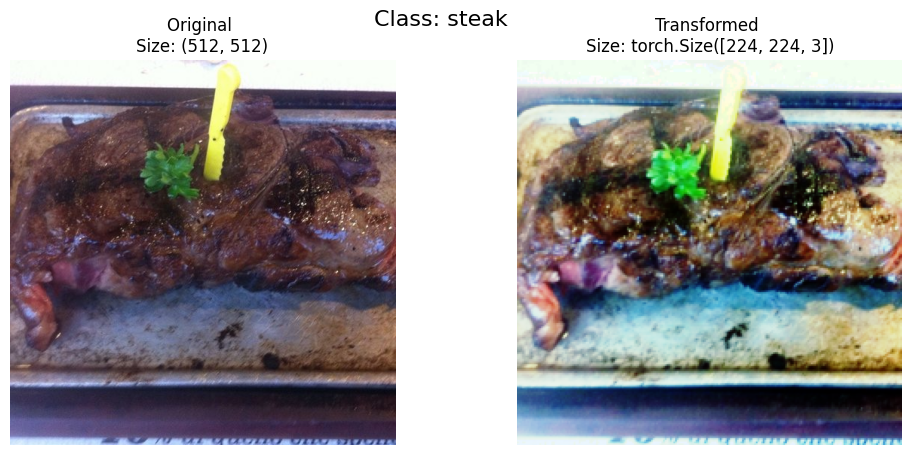

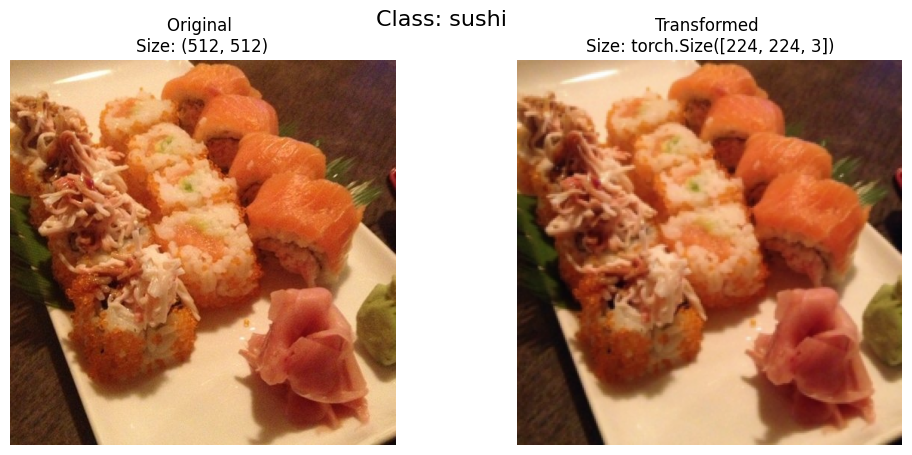

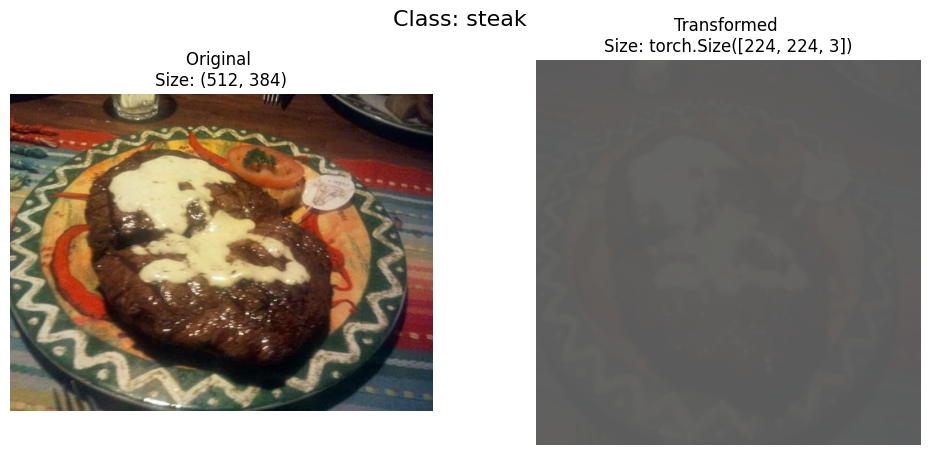

In [29]:
# Get all image paths
image_path_list = list(image_path.glob("*/*/*.jpg"))

# Plot random images
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transforms,
    n=3,
    seed=None
)

# <span style="color:magenta">4. Model 0: TinyVGG without data Augmentation</span>

### 7.1 Creating transform and Loading data.

In [30]:
import torch.nn as nn

In [59]:
# Create simple transform
simple_transform = transforms.Compose([ 
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

In [32]:
# 1. Load and transform data
train_data_simple = datasets.ImageFolder(root=train_dir, transform=simple_transform)
test_data_simple = datasets.ImageFolder(root=test_dir, transform=simple_transform)

# 2. Turn data into DataLoaders
# Setup batch size and number of workers 
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()
print(f"Creating DataLoader's with batch size {BATCH_SIZE} and {NUM_WORKERS} workers.")

# Create DataLoader's
train_dataloader_simple = DataLoader(train_data_simple, 
                                     batch_size=BATCH_SIZE, 
                                     shuffle=True, 
                                     num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_simple, test_dataloader_simple

Creating DataLoader's with batch size 32 and 8 workers.


(<torch.utils.data.dataloader.DataLoader at 0x7f420198f8f0>,
 <torch.utils.data.dataloader.DataLoader at 0x7f4201d53a70>)

### 4.2 Create TinyVGG model

In [60]:
class TinyVGG(nn.Module):
    """
    Model architecture copying TinyVGG from: 
    https://poloclub.github.io/cnn-explainer/
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_units, 
                      kernel_size=3, # how big is the square that's going over the image?
                      stride=1, # default
                      padding=1), # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number 
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from? 
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        # print(x.shape)
        x = self.conv_block_2(x)
        # print(x.shape)
        x = self.classifier(x)
        # print(x.shape)
        return x
        # return self.classifier(self.conv_block_2(self.conv_block_1(x))) # <- leverage the benefits of operator fusion

torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB) 
                  hidden_units=10, 
                  output_shape=len(train_data.classes)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [41]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader_simple))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
model_0.eval()
with torch.inference_mode():
    pred = model_0(img_single.to(device))
    
# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 64, 64])

Output logits:
tensor([[0.0632, 0.0599, 0.0366]])

Output prediction probabilities:
tensor([[0.3366, 0.3355, 0.3278]])

Output prediction label:
tensor([0])

Actual label:
1


In [ ]:
import torchinfo
from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64])       # do a test pass through of an example input size

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

In [44]:
def train_step(model: torch.nn.Module, 
               dataloader: torch.utils.data.DataLoader, 
               loss_fn: torch.nn.Module, 
               optimizer: torch.optim.Optimizer):
    # Put model in train mode
    model.train()
    
    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0
    
    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        # Send data to target device
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item() 

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metrics across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch 
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [45]:
def test_step(model: torch.nn.Module, 
              dataloader: torch.utils.data.DataLoader, 
              loss_fn: torch.nn.Module):
    # Put model in eval mode
    model.eval() 
    
    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0
    
    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            # Send data to target device
            X, y = X.to(device), y.to(device)
    
            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()
            
            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))
            
    # Adjust metrics to get average loss and accuracy per batch 
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [46]:
from tqdm.auto import tqdm

# 1. Take in various parameters required for training and test steps
def train(model: torch.nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    
    # 2. Create empty results dictionary
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }
    
    # 3. Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)
        
        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

In [47]:
# Set random seeds
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 5

# Recreate an instance of TinyVGG
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB) 
                  hidden_units=10, 
                  output_shape=len(train_data.classes)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Train model_0 
model_0_results = train(model=model_0, 
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1078 | train_acc: 0.2578 | test_loss: 1.1362 | test_acc: 0.2604
Epoch: 2 | train_loss: 1.0846 | train_acc: 0.4258 | test_loss: 1.1622 | test_acc: 0.1979
Epoch: 3 | train_loss: 1.1155 | train_acc: 0.2930 | test_loss: 1.1698 | test_acc: 0.1979
Epoch: 4 | train_loss: 1.0975 | train_acc: 0.4141 | test_loss: 1.1360 | test_acc: 0.1979
Epoch: 5 | train_loss: 1.0990 | train_acc: 0.2930 | test_loss: 1.1425 | test_acc: 0.1979
Total training time: 8.202 seconds


In [48]:
# Check the model_0_results keys
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [49]:
def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """
    
    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot 
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

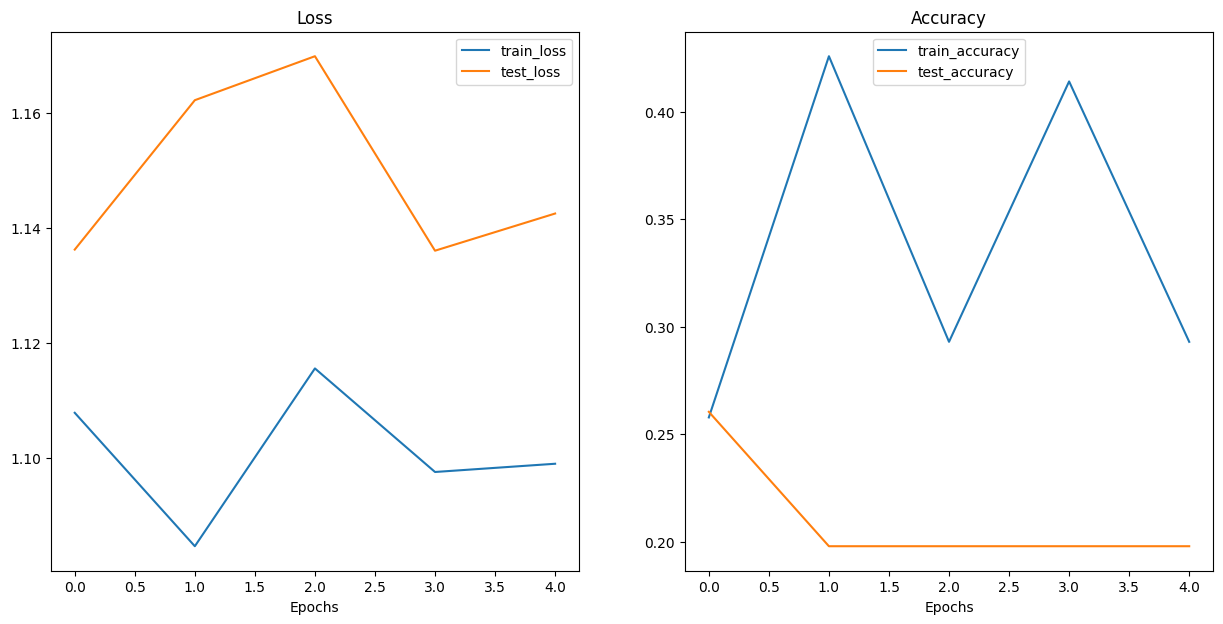

In [50]:
plot_loss_curves(model_0_results)

In [51]:
# Create training transform with TrivialAugment
train_transform_trivial_augment = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor() 
])

# Create testing transform (no data augmentation)
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [52]:
# Turn image folders into Datasets
train_data_augmented = datasets.ImageFolder(train_dir, transform=train_transform_trivial_augment)
test_data_simple = datasets.ImageFolder(test_dir, transform=test_transform)

train_data_augmented, test_data_simple

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: /home/nigatie/Documents/ML_DL/Deep_Learning/Dataset/food_images/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [53]:
# Turn Datasets into DataLoader's
import os
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)
train_dataloader_augmented = DataLoader(train_data_augmented, 
                                        batch_size=BATCH_SIZE, 
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_augmented, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7f4255764aa0>,
 <torch.utils.data.dataloader.DataLoader at 0x7f4201bdbaa0>)

In [54]:
# Create model_1 and send it to the target device
torch.manual_seed(42)
model_1 = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [55]:
# Set random seeds
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 5

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Train model_1
model_1_results = train(model=model_1, 
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1074 | train_acc: 0.2500 | test_loss: 1.1059 | test_acc: 0.2604
Epoch: 2 | train_loss: 1.0790 | train_acc: 0.4258 | test_loss: 1.1384 | test_acc: 0.2604
Epoch: 3 | train_loss: 1.0804 | train_acc: 0.4258 | test_loss: 1.1688 | test_acc: 0.2604
Epoch: 4 | train_loss: 1.1286 | train_acc: 0.3047 | test_loss: 1.1625 | test_acc: 0.2604
Epoch: 5 | train_loss: 1.0883 | train_acc: 0.4258 | test_loss: 1.1483 | test_acc: 0.2604
Total training time: 8.265 seconds


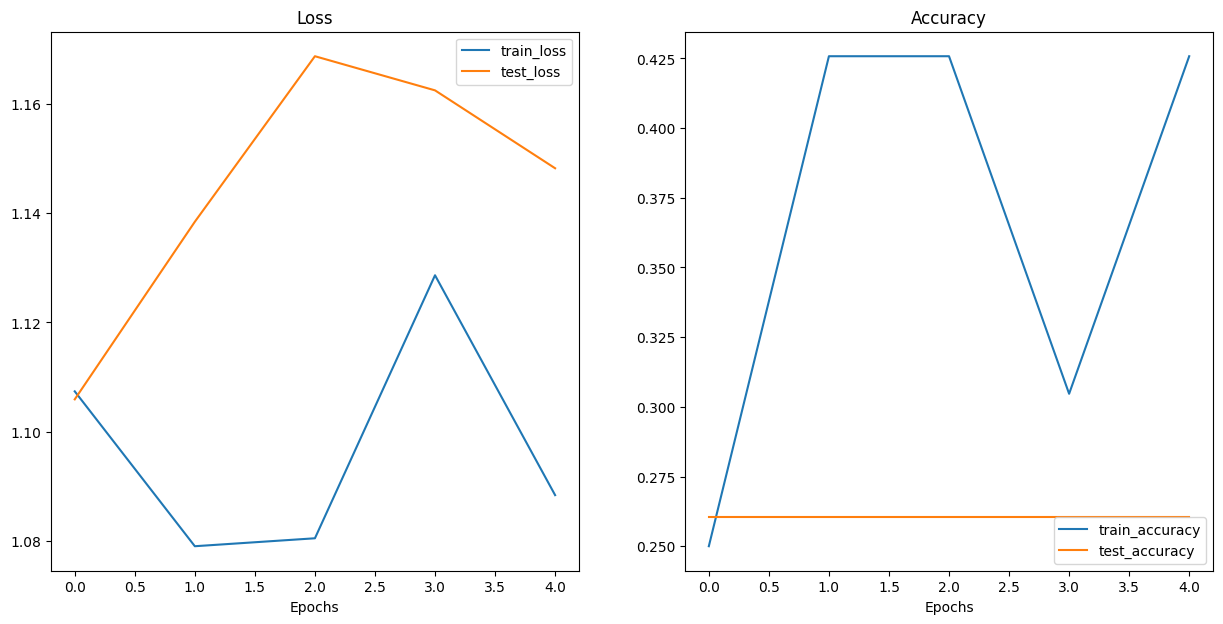

In [56]:
plot_loss_curves(model_1_results)

In [57]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.107836,0.257812,1.136210,0.260417
1,1.084636,0.425781,1.162185,0.197917
2,1.115547,0.292969,1.169830,0.197917
3,1.097544,0.414062,1.136017,0.197917
4,1.098975,0.292969,1.142480,0.197917


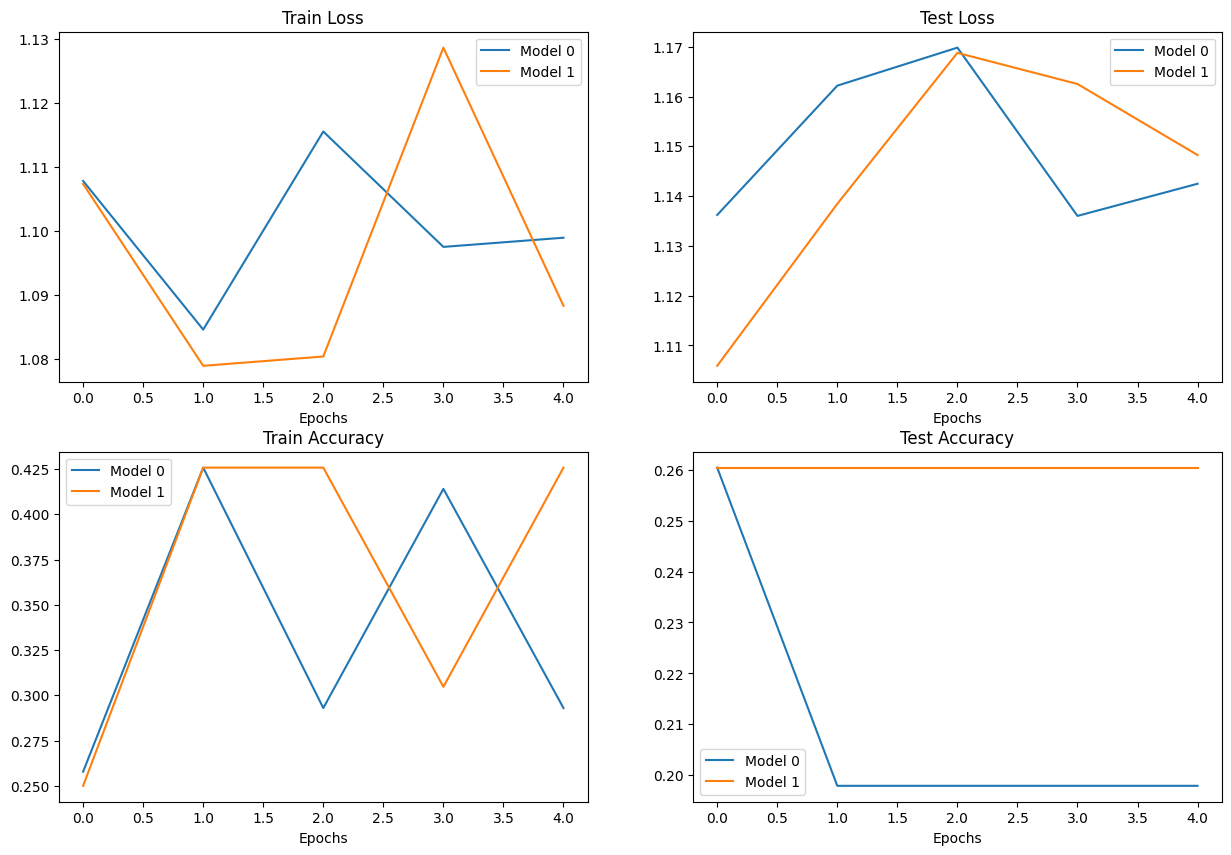

In [58]:
# Setup a plot 
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();